In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib
import numpy as np
import scipy.optimize
import odrpack

plt.rcParams["figure.dpi"] = 150
plt.rcParams["text.usetex"] = True
plt.rcParams["font.size"] = 12


# matplotlib.rcParams['mathtext.fontset'] = 'stix'
# matplotlib.rcParams['font.family'] = 'Computer Modern'


plt.rcParams['font.family'] = 'serif' # or 'sans-serif' or 'monospace'
plt.rcParams['font.serif'] = 'cmr10'
plt.rcParams['font.sans-serif'] = 'cmss10'
plt.rcParams['font.monospace'] = 'cmtt10'
plt.rcParams["axes.formatter.use_mathtext"] = True # to fix the minus signs
%config InlineBackend.figure_format = 'retina'
#plt.rcParams['axes.grid'] = True

In [2]:
def string_to_float_list(data_string: str):
    return np.array([float(x) for x in data_string.split()])

In [3]:
electron_charge = 1.60217663e-19 #In coulombs
c = 299792458 # m / s


In [4]:
red_voltages = string_to_float_list("""488
443
364
260
189
75
40
-1
-41
-79
-132
-202
-254
-279
-289
-303
-316
-342
-365
-473
-557
""")

red_currents = string_to_float_list("""3922
3639
3122
2384
1892
1102
852
604
424
265
131
38
7
7
3
3
-1
0
-7
-7
-7
""")



green_voltages = string_to_float_list("""478
367
223
152
93
-1
-52
-88
-119
-151
-225
-307
-440
-529
-588
-619
-632
-682
-732
-886
-1040
""")

green_currents = string_to_float_list("""7733
6550
5015
4279
3661
2663
2189
1870
1635
1393
905
500
140
45
14
3
0
-1
-4
-8
-4
""")

blue_voltages = string_to_float_list("""415
283
131
70
40
0
-22
-55
-178
-246
-329
-438
-674
-800
-867
-918
-992
-1190
-1270
-1440
""")

blue_currents = string_to_float_list("""14670
12280
9618
9079
8541
7847
7481
6736
4984
4055
3031
1954
459
109
10
-3
-5
-8
-8
-8
""")


red_voltage_err = np.full(len(red_voltages), 1)
red_current_err = np.full(len(red_currents), 8)
green_voltage_err = np.full(len(green_voltages), 1)
green_current_err = np.full(len(green_currents), 8)
blue_voltage_err = np.full(len(blue_voltages), 1)
blue_current_err = np.full(len(blue_currents), 8)

In [5]:
def IV_func(v, m, v0, offset):
    return np.piecewise(v, [v >= v0], [lambda x: m*(x-v0) + offset, lambda x: offset])

In [6]:
popt_IV_R, pcov_IV_R = scipy.optimize.curve_fit(IV_func, red_voltages, red_currents)
popt_IV_G, pcov_IV_G = scipy.optimize.curve_fit(IV_func, green_voltages, green_currents)

popt_IV_B, pcov_IV_B = scipy.optimize.curve_fit(IV_func, blue_voltages, blue_currents)


# red_V_stop = popt_IV_R[1]
# green_V_stop = popt_IV_G[1]
# blue_V_stop = popt_IV_B[1]

In [7]:

slope_cutoff = 0.15

red_idx = np.argmax(np.gradient(red_currents, red_voltages) < slope_cutoff*np.max(np.gradient(red_currents, red_voltages))).item()
red_V_stop = red_voltages[red_idx]

red_V_stop_err = min(abs(red_voltages[red_idx] - red_voltages[red_idx - 1]), abs(red_voltages[red_idx] - red_voltages[red_idx + 1])) / 2

green_idx = np.argmax(np.gradient(green_currents, green_voltages) < slope_cutoff*np.max(np.gradient(green_currents, green_voltages))).item()
green_V_stop = green_voltages[green_idx]

green_V_stop_err = min(abs(green_voltages[green_idx] - green_voltages[green_idx - 1]), abs(green_voltages[green_idx] - green_voltages[green_idx + 1])) / 2

blue_idx = np.argmax(np.gradient(blue_currents, blue_voltages) < slope_cutoff*np.max(np.gradient(blue_currents, blue_voltages))).item()
blue_V_stop = blue_voltages[blue_idx]
blue_V_stop_err = min(abs(blue_voltages[blue_idx] - blue_voltages[blue_idx - 1]), abs(blue_voltages[blue_idx] - blue_voltages[blue_idx + 1])) / 2



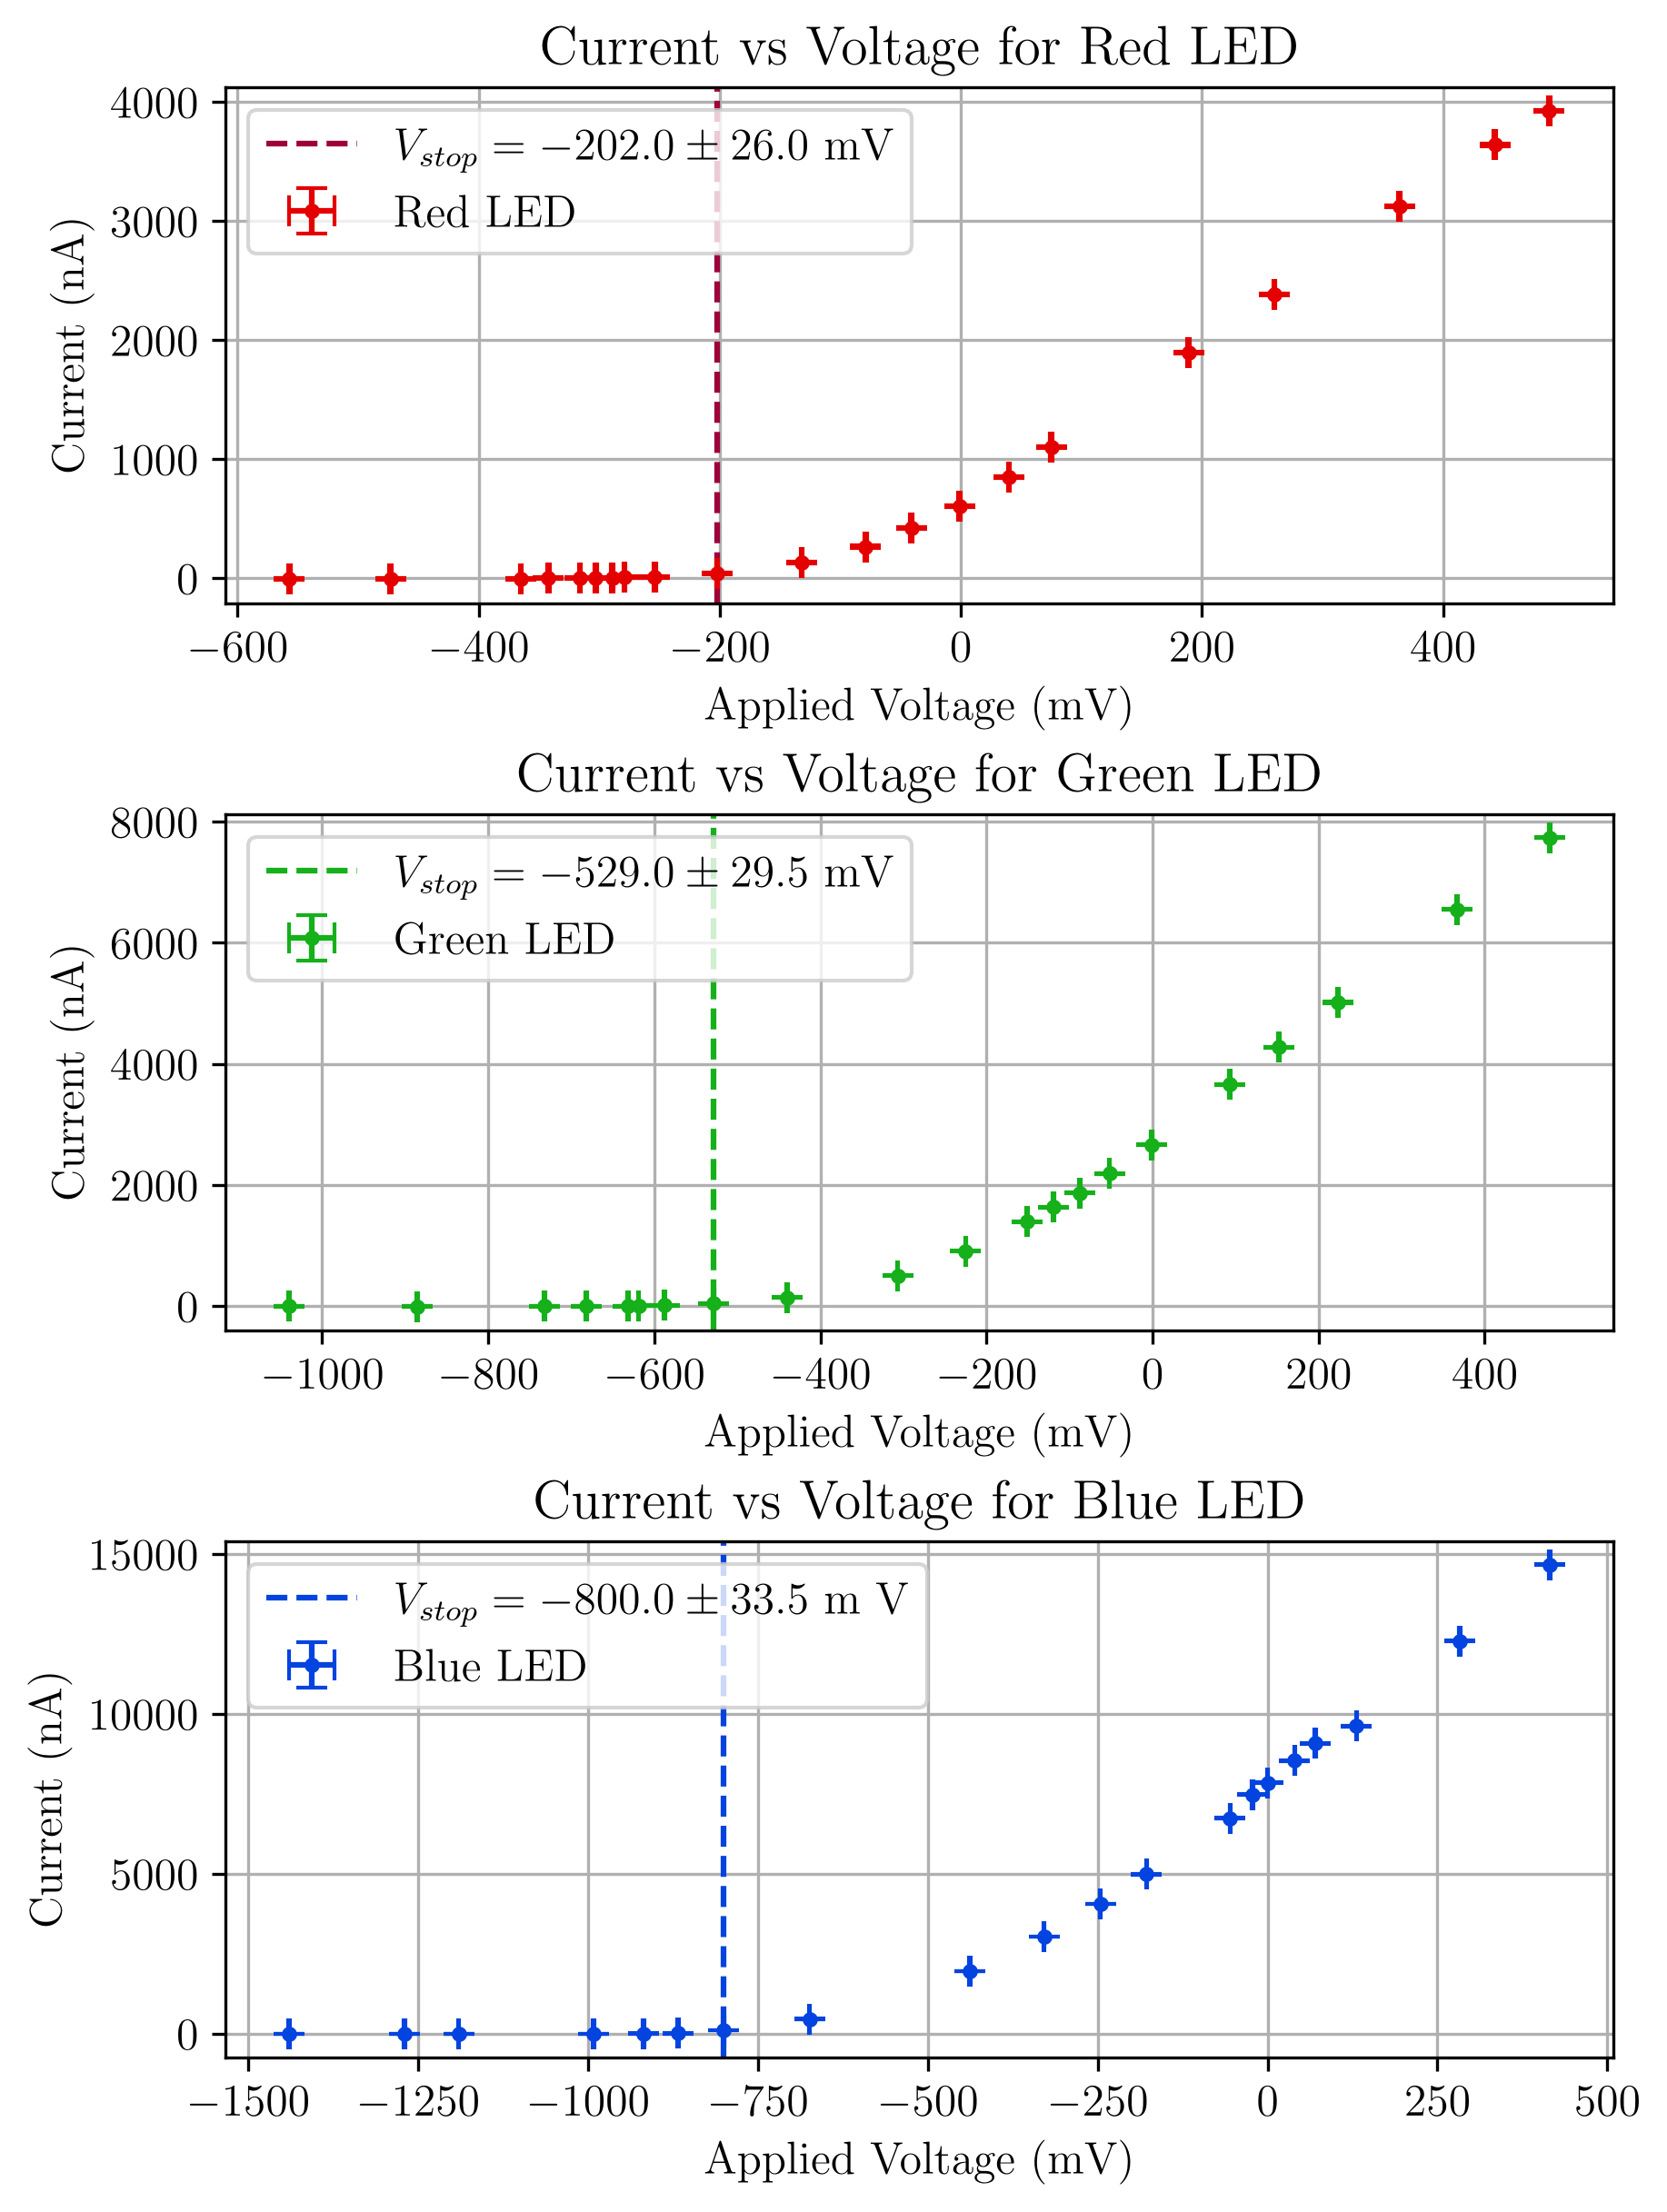

In [8]:
IV_fig, IV_axs = plt.subplots(3, figsize=(6, 8), layout="constrained")

IV_axs[0].grid()
IV_axs[1].grid()
IV_axs[2].grid()


#IV_axs[1].plot(np.linspace(green_voltages.min(), green_voltages.max(), 200), IV_func(np.linspace(green_voltages.min(), green_voltages.max(), 200), *popt_IV_G))

IV_axs[0].errorbar(red_voltages, red_currents, red_current_err, red_voltage_err, fmt = 'o', markersize = 3, capsize = 4, color = 'xkcd:red', zorder=10, label = "Red LED")
IV_axs[1].errorbar(green_voltages, green_currents, green_current_err, green_voltage_err, fmt = 'o', markersize = 3, capsize = 4, color = 'xkcd:green', zorder=10, label = "Green LED")
IV_axs[2].errorbar(blue_voltages, blue_currents, blue_current_err, blue_voltage_err, fmt = 'o', markersize = 3, capsize = 4, color = 'xkcd:blue', zorder=10, label = "Blue LED")


IV_axs[0].axvline(red_V_stop, color = 'xkcd:cranberry', linestyle="dashed",label=rf"$V_{{stop}} = {red_V_stop:0.1f} \pm {red_V_stop_err:0.1f}$ mV")
IV_axs[1].axvline(green_V_stop, color = 'xkcd:green', linestyle="dashed",label=rf"$V_{{stop}} = {green_V_stop:0.1f} \pm {green_V_stop_err:0.1f}$ mV")
IV_axs[2].axvline(blue_V_stop, color = 'xkcd:blue', linestyle="dashed",label=rf"$V_{{stop}} = {blue_V_stop:0.1f} \pm {blue_V_stop_err:0.1f}$ m  V")


IV_axs[0].legend()
IV_axs[1].legend()
IV_axs[2].legend()

IV_axs[0].set_xlabel("Applied Voltage (mV)")
IV_axs[0].set_ylabel("Current (nA)")
IV_axs[1].set_xlabel("Applied Voltage (mV)")
IV_axs[1].set_ylabel("Current (nA)")
IV_axs[2].set_xlabel("Applied Voltage (mV)")
IV_axs[2].set_ylabel("Current (nA)")


IV_axs[0].set_title("Current vs Voltage for Red LED")
IV_axs[1].set_title("Current vs Voltage for Green LED")
IV_axs[2].set_title("Current vs Voltage for Blue LED")


IV_fig.savefig("plots/led_IV_curves.png", dpi=300)

In [9]:
red_wavelength_min = 586.1e-9
red_wavelength_max = 625.1e-9
red_wavelength = (red_wavelength_max + red_wavelength_min) / 2
red_wavelength_err = (red_wavelength_max - red_wavelength_min) / 2

green_wavelength_min = 480.5e-9
green_wavelength_max = 634.4e-9
green_wavelength = (green_wavelength_max + green_wavelength_min) / 2
green_wavelength_err = (green_wavelength_max - green_wavelength_min) / 2

blue_wavelength_min = 411.9e-9
blue_wavelength_max = 531.7e-9
blue_wavelength = (blue_wavelength_max + blue_wavelength_min) / 2
blue_wavelength_err = (blue_wavelength_max - blue_wavelength_min) / 2

print(blue_wavelength*1e9, blue_wavelength_err*1e9)

471.79999999999995 59.90000000000003


In [10]:
def fit_curve(x, m, x0):
    return m*(x - x0)

wavelengths = np.array([red_wavelength, green_wavelength, blue_wavelength])
wavelengths_err = np.array([red_wavelength_err, green_wavelength_err, blue_wavelength_err])

freqs = c / wavelengths
freqs_err = wavelengths_err * c / (wavelengths**2)

K_max = np.abs(np.array([red_V_stop, green_V_stop, blue_V_stop])) * 1e-3
K_max_err = np.array([red_V_stop_err, green_V_stop_err, blue_V_stop_err]) * 1e-3

popt_naive, pcov_naive = scipy.optimize.curve_fit(fit_curve, freqs, K_max, p0 = (4e-15, 5e14))

equiv_err = np.sqrt((popt_naive[0] * freqs_err)**2 + K_max_err**2)

popt, pcov = scipy.optimize.curve_fit(fit_curve, freqs, K_max, sigma = equiv_err, p0 = (4e-15, 5e14))

slope = popt[0]
f0 = popt[1]

slope_err = np.sqrt(pcov[0][0])
f0_err = np.sqrt(pcov[1][1])

7.2949284659245625e-34
0.16067332111187235


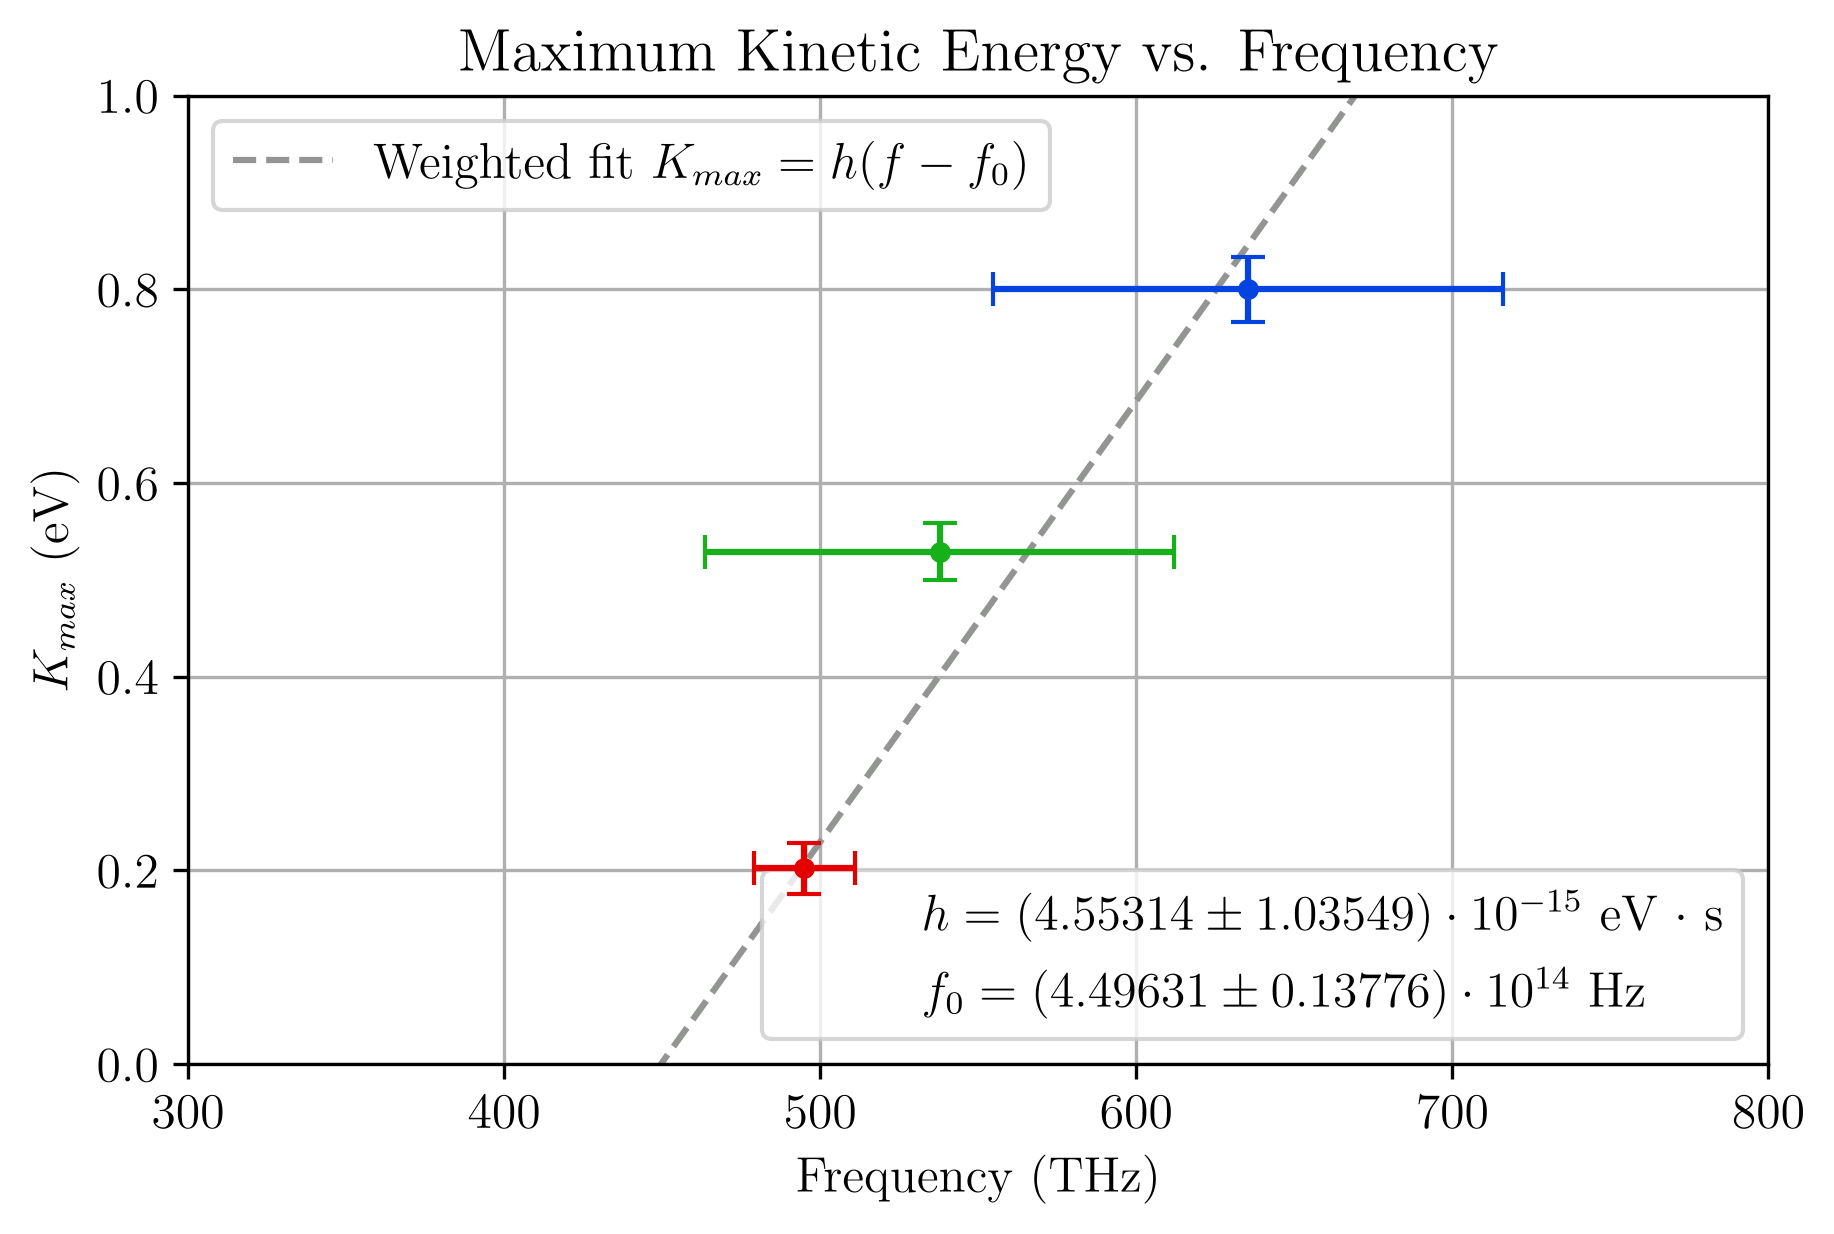

In [11]:


Kmax_fig, Kmax_ax = plt.subplots(1, figsize=(6, 4), layout="constrained")

colors = ["xkcd:red", "xkcd:green", "xkcd:blue"]
for i in range(len(freqs)):
    Kmax_ax.errorbar(freqs[i], K_max[i], yerr = K_max_err[i], xerr = freqs_err[i], color = colors[i], fmt = 'o', markersize = 4, capsize = 4, zorder=10)

xvals = np.linspace(0, max(freqs)*1.5)
Kmax_ax.plot(xvals, fit_curve(xvals, slope, f0), color = 'xkcd:gray', linestyle="dashed", label = rf"Weighted fit $K_{{max}} = h(f - f_0)$")


Kmax_ax.set_ylim(0.0, 1.0)
Kmax_ax.set_xlim(3e14, 8e14)

Kmax_ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x * 1e-12:.0f}'))
Kmax_ax.set_xlabel(r"Frequency (THz)")

Kmax_ax.set_ylabel(r"$K_{max}$ (eV)")

Kmax_ax.set_title(r"Maximum Kinetic Energy vs. Frequency")

Kmax_ax.grid()
legend = Kmax_ax.legend()

Kmax_ax.add_artist(legend)



print(slope * electron_charge)
custom_elements = [
    matplotlib.patches.Patch(color="None", linestyle = "dashed", label=rf"$h = ({slope * 1e15:0.5f} \pm {slope_err * 1e15:0.5f}) \cdot 10^{{-15}}$ eV $\cdot$ s"),
    matplotlib.patches.Patch(color="None", linestyle = "dashed", label=rf"$f_0 = ({f0*1e-14:0.5f} \pm {f0_err*1e-14:0.5f}) \cdot 10^{{14}}$ Hz")
]
Kmax_ax.legend(handles=custom_elements, loc='lower right')


Kmax_fig.savefig("plots/led_KE_vs_f.png", dpi=300)

chi2 = np.sum((K_max - fit_curve(freqs, slope, f0))**2 / (K_max_err**2 + (slope*freqs_err)**2))

print(chi2)